<a href="https://colab.research.google.com/github/BrynX5/econ-project/blob/main/labor_market_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecasting U.S. Unemployment from Labor Market Indicators

**Question:** Can last quarter's labor market and macro indicators forecast next quarter's unemployment rate better than assuming it stays the same?

**Approach**
1. Pull 9 public series from FRED (no API key needed) and aggregate them to quarters.
2. Use each indicator **one quarter earlier** to predict the **change** in unemployment, so this is a true forecast.
3. Evaluate with a **walk-forward test**: retrain every quarter on only past data, then predict the next quarter.
4. Compare a random forest against two baselines: *no change* (next quarter = this quarter) and a linear model.

All errors are in **percentage points** of the unemployment rate.

In [13]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
SEED = 42

## 1. Data

Each series is read from FRED's public CSV download, so no API key is needed. Series observed more often than quarterly are averaged within each quarter.

In [14]:
SERIES = {
    "unemployment":   "UNRATE",           # unemployment rate, %, monthly
    "job_openings":   "JTSJOL",           # JOLTS job openings, thousands, monthly (starts Dec 2000)
    "cpi":            "CPIAUCSL",         # CPI, index, monthly
    "gdp_growth":     "A191RL1Q225SBEA",  # real GDP growth, annualized %, quarterly
    "lfpr":           "CIVPART",          # labor force participation rate, %, monthly
    "avg_wages":      "CES0500000003",    # average hourly earnings, $, monthly
    "yield_spread":   "T10Y2Y",           # 10-year minus 2-year Treasury, %, daily
    "initial_claims": "ICSA",             # initial jobless claims, weekly
    "pce":            "PCE",              # personal consumption expenditures, $bn, monthly
}

def fred(series_id: str) -> pd.Series:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    raw = pd.read_csv(url)
    s = pd.to_numeric(raw.iloc[:, 1], errors="coerce")   # FRED marks missing days with "."
    s.index = pd.to_datetime(raw.iloc[:, 0])
    return s.dropna()

raw = {name: fred(code) for name, code in SERIES.items()}
q = pd.DataFrame({name: s.resample("QS").mean() for name, s in raw.items()}).dropna()
q = q[q.index < pd.Timestamp.today().to_period("Q").start_time]   # drop the incomplete current quarter
print(f"{len(q)} quarters, {q.index.min().to_period('Q')} to {q.index.max().to_period('Q')}")
q.tail()

83 quarters, 2006Q1 to 2026Q3


,unemployment,job_openings,cpi,gdp_growth,lfpr,avg_wages,yield_spread,initial_claims,pce
observation_date,,,,,,,,,
2025-07-01,4.333333,7059.000000,323.235000,3.9,62.333333,36.596667,0.540312,228461.538462,21027.733333
2025-10-01,4.450000,6855.333333,325.547000,0.2,62.450000,36.956667,0.577581,222769.230769,21268.866667
2026-01-01,4.333333,7016.333333,328.113667,2.5,62.000000,37.256667,0.617213,211846.153846,21526.000000
2026-04-01,4.266667,7434.666667,332.984667,2.2,61.700000,37.496667,0.456032,213769.230769,21993.200000
2026-07-01,4.133333,7349.333333,334.414000,3.4,61.600000,37.753333,0.393906,203461.538462,22312.833333


## 2. Features: last quarter's indicators, this quarter's change

Price, wage and spending levels trend upward forever, so they enter as year-over-year growth rates. Every feature is lagged one quarter. The target is the **change** in unemployment, which keeps the random forest from having to extrapolate to levels it has never seen.

In [15]:
f = pd.DataFrame(index=q.index)
f["unemployment"]       = q["unemployment"]
f["d_unemployment"]     = q["unemployment"].diff()
f["job_openings_yoy"]   = q["job_openings"].pct_change(4) * 100
f["inflation_yoy"]      = q["cpi"].pct_change(4) * 100
f["gdp_growth"]         = q["gdp_growth"]
f["lfpr"]               = q["lfpr"]
f["wage_growth_yoy"]    = q["avg_wages"].pct_change(4) * 100
f["yield_spread"]       = q["yield_spread"]
f["claims_yoy"]         = q["initial_claims"].pct_change(4) * 100
f["pce_growth_yoy"]     = q["pce"].pct_change(4) * 100

FEATURES = [c for c in f.columns]                 # all of them, as of LAST quarter
X = f[FEATURES].shift(1).add_suffix("_lag1")
data = X.assign(target=f["d_unemployment"], u_prev=f["unemployment"].shift(1),
                u_now=f["unemployment"]).dropna()
print(f"{len(data)} usable quarters after lags, {data.index.min().to_period('Q')} to {data.index.max().to_period('Q')}")
data.head()

78 usable quarters after lags, 2007Q2 to 2026Q3


,unemployment_lag1,d_unemployment_lag1,job_openings_yoy_lag1,inflation_yoy_lag1,gdp_growth_lag1,lfpr_lag1,wage_growth_yoy_lag1,yield_spread_lag1,claims_yoy_lag1,pce_growth_yoy_lag1,target,u_prev,u_now
observation_date,,,,,,,,,,,,,
2007-04-01,4.500000,0.066667,7.209752,2.431651,1.2,66.300000,3.110446,-0.081452,6.700730,5.186352,0.000000,4.500000,4.500000
2007-07-01,4.500000,0.000000,2.437441,2.665287,2.5,65.966667,3.403833,0.042344,0.073692,4.888199,0.166667,4.500000,4.666667
2007-10-01,4.666667,0.166667,-0.325121,2.348975,2.3,65.933333,3.228979,0.347619,-0.374896,4.752792,0.133333,4.666667,4.800000
2008-01-01,4.800000,0.133333,-0.209296,4.031137,2.5,65.933333,3.008619,0.776935,5.039408,5.407307,0.200000,4.800000,5.000000
2008-04-01,5.000000,0.200000,-8.985025,4.137035,-1.7,66.100000,2.952089,1.635902,11.005600,4.516583,0.333333,5.000000,5.333333


## 3. Walk-forward test

The last 20% of quarters are the test period. For each test quarter, every model is retrained on all earlier quarters only, then forecasts that one quarter. This is how the model would have performed in real time.

In [16]:
feat_cols = [c for c in data.columns if c.endswith("_lag1")]
n_test = max(8, int(round(len(data) * 0.2)))
test_idx = data.index[-n_test:]

models = {
    "random_forest": lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED),
    "linear_ridge":  lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
}

rows = []
for t in test_idx:
    train = data[data.index < t]
    row = {"quarter": t, "actual": data.at[t, "u_now"], "no_change": data.at[t, "u_prev"]}
    for name, make in models.items():
        m = make().fit(train[feat_cols], train["target"])
        row[name] = data.at[t, "u_prev"] + m.predict(data.loc[[t], feat_cols])[0]
    rows.append(row)
pred = pd.DataFrame(rows).set_index("quarter")

mae = {name: float((pred[name] - pred["actual"]).abs().mean()) for name in ["no_change", *models]}
results = pd.DataFrame({"MAE (pct points)": mae}).sort_values("MAE (pct points)")
results["vs no-change baseline"] = (results["MAE (pct points)"] / mae["no_change"] - 1).map("{:+.0%}".format)
print(f"Test period: {test_idx.min().to_period('Q')} to {test_idx.max().to_period('Q')} ({n_test} quarters), one quarter ahead")
results

Test period: 2022Q4 to 2026Q3 (16 quarters), one quarter ahead


,MAE (pct points),vs no-change baseline
linear_ridge,0.083323,-2%
no_change,0.085417,+0%
random_forest,0.130905,+53%


## 4. Which indicators matter?

The random forest is refit on all quarters to rank features by importance. Importance shows what the model relies on, not cause and effect.

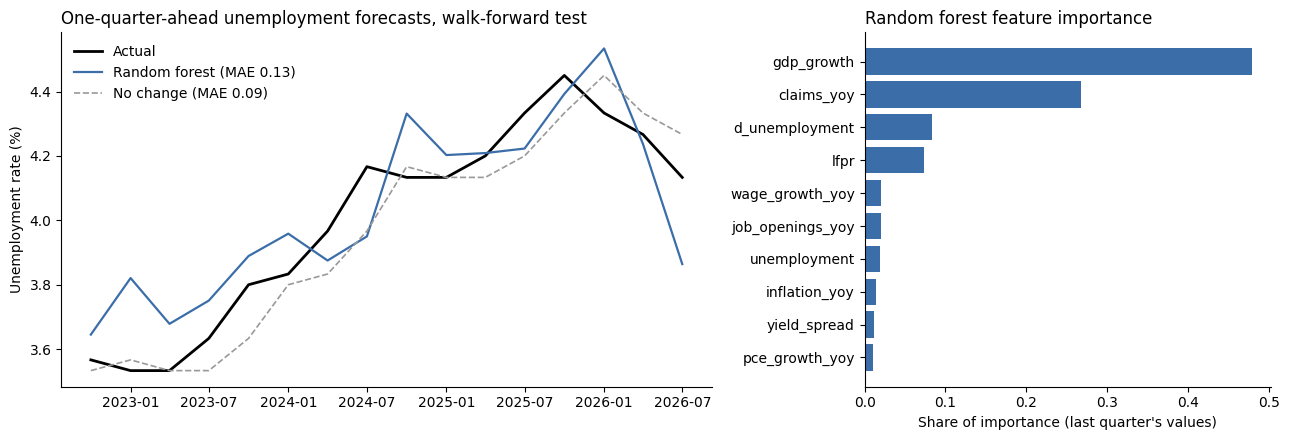

In [17]:
rf_full = models["random_forest"]().fit(data[feat_cols], data["target"])
imp = (pd.Series(rf_full.feature_importances_, index=[c.replace("_lag1", "") for c in feat_cols])
         .sort_values())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(pred.index, pred["actual"], color="black", lw=2, label="Actual")
ax.plot(pred.index, pred["random_forest"], color="#3b6ea8", lw=1.6, label=f"Random forest (MAE {mae['random_forest']:.2f})")
ax.plot(pred.index, pred["no_change"], color="#999", lw=1.2, ls="--", label=f"No change (MAE {mae['no_change']:.2f})")
ax.set_title("One-quarter-ahead unemployment forecasts, walk-forward test", loc="left")
ax.set_ylabel("Unemployment rate (%)")
ax.legend(frameon=False)

ax = axes[1]
ax.barh(imp.index, imp.values, color="#3b6ea8")
ax.set_title("Random forest feature importance", loc="left")
ax.set_xlabel("Share of importance (last quarter's values)")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figures/forecast_and_importance.png", dpi=200)
plt.show()

In [18]:
summary = {
    "quarters_used": int(len(data)),
    "sample": f"{data.index.min().to_period('Q')} to {data.index.max().to_period('Q')}",
    "test_period": f"{test_idx.min().to_period('Q')} to {test_idx.max().to_period('Q')}",
    "test_quarters": int(n_test),
    "mae_pct_points": {k: round(v, 3) for k, v in mae.items()},
    "rf_vs_no_change": round(mae["random_forest"] / mae["no_change"] - 1, 3),
    "top_features": imp.sort_values(ascending=False).head(3).round(3).to_dict(),
}
Path("results/metrics.json").write_text(json.dumps(summary, indent=2))
pred.round(3).to_csv("results/walk_forward_predictions.csv")
print(json.dumps(summary, indent=2))

{
  "quarters_used": 78,
  "sample": "2007Q2 to 2026Q3",
  "test_period": "2022Q4 to 2026Q3",
  "test_quarters": 16,
  "mae_pct_points": {
    "no_change": 0.085,
    "random_forest": 0.131,
    "linear_ridge": 0.083
  },
  "rf_vs_no_change": 0.533,
  "top_features": {
    "gdp_growth": 0.479,
    "claims_yoy": 0.268,
    "d_unemployment": 0.083
  }
}


# Part 2: Monthly forecasts at several horizons

Part 1 found that nothing beat "no change" one quarter ahead. Part 2 tests three fixes:

1. **Monthly data, starting in 1977**, so the model sees the newest numbers and has about 7 times as many observations. The JOLTS, wage and spending series are dropped because they start too late.
2. **Weekly jobless claims**, the most timely labor market signal, averaged to months.
3. **Small linear models**, which usually beat tree models on short economic series.

Every model forecasts the change in unemployment **1, 3, 6 and 12 months ahead**, from information available at the time of the forecast. Months from March 2020 to June 2021 are left out of training and scoring, so the COVID shock can't dominate. Errors are also reported for recession months alone, using the NBER recession dates on FRED.

In [19]:
M_SERIES = {
    "unemployment":   "UNRATE",   # monthly, %
    "initial_claims": "ICSA",     # weekly
    "yield_spread":   "T10Y2Y",   # daily, 10y minus 2y Treasury
    "recession":      "USREC",    # NBER recession indicator, monthly (1 = recession)
}
m = pd.DataFrame({k: fred(v).resample("MS").mean() for k, v in M_SERIES.items()})
m = m[(m.index >= "1977-01-01") & (m.index < pd.Timestamp.today().to_period("M").start_time)].dropna()
print(f"{len(m)} months, {m.index.min():%Y-%m} to {m.index.max():%Y-%m}")

u, claims = m["unemployment"], np.log(m["initial_claims"])
mf = pd.DataFrame({
    "du_1m":        u.diff(1),                       # last month's change in unemployment
    "du_3m":        u.diff(3),                       # last 3 months' change
    "sahm_gap":     u.rolling(3).mean() - u.rolling(12).min(),   # rise above the 12-month low (Sahm-rule style)
    "claims_3m":    claims.diff(3) * 100,            # % change in claims over 3 months
    "claims_12m":   claims.diff(12) * 100,           # % change in claims over 12 months
    "yield_spread": m["yield_spread"],
}, index=m.index)

AR_FEATS = ["du_1m", "du_3m"]                         # unemployment's own recent changes only
ARX_FEATS = AR_FEATS + ["sahm_gap", "claims_3m", "claims_12m", "yield_spread"]
COVID = (pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"))
mf.tail()

597 months, 1977-01 to 2026-10


,du_1m,du_3m,sahm_gap,claims_3m,claims_12m,yield_spread
observation_date,,,,,,
2026-06-01,-0.1,-0.1,0.166667,6.738902,-4.094783,0.357619
2026-07-01,-0.1,-0.2,0.100000,-2.189869,-16.202680,0.376818
2026-08-01,0.0,-0.2,0.033333,-2.682153,-7.254642,0.468095
2026-09-01,0.1,0.0,0.033333,-10.411285,-13.552442,0.337619
2026-10-01,-0.1,0.0,0.033333,-3.938801,-18.027238,0.387619


In [20]:
from sklearn.linear_model import LinearRegression

HORIZONS = [1, 3, 6, 12]
TEST_START = pd.Timestamp("2000-01-01")    # covers the 2001 and 2008-09 recessions
REFIT_EVERY = 12                           # re-estimate once a year, as a forecaster would

m_models = {
    "ar":            (AR_FEATS,  lambda: LinearRegression()),
    "ar_claims":     (ARX_FEATS, lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))),
    "random_forest": (ARX_FEATS, lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
}

def in_covid(dates):
    return (dates >= COVID[0]) & (dates <= COVID[1])

rows = []
for h in HORIZONS:
    d = mf.assign(target=u.shift(-h) - u, u_now=u, u_future=u.shift(-h),
                  rec_future=m["recession"].shift(-h)).dropna()
    target_date = d.index + pd.DateOffset(months=h)
    d = d[~in_covid(d.index) & ~in_covid(target_date)]
    test_dates = d.index[d.index >= TEST_START]
    fitted, last_fit = {}, None
    for t in test_dates:
        if last_fit is None or (t.year * 12 + t.month) - (last_fit.year * 12 + last_fit.month) >= REFIT_EVERY:
            train = d[d.index + pd.DateOffset(months=h) <= t]   # only targets already observed at time t
            fitted = {k: mk().fit(train[f], train["target"]) for k, (f, mk) in m_models.items()}
            last_fit = t
        row = {"horizon": h, "date": t, "actual": d.at[t, "u_future"],
               "no_change": d.at[t, "u_now"], "recession": d.at[t, "rec_future"] == 1}
        for k, (f, _) in m_models.items():
            row[k] = d.at[t, "u_now"] + fitted[k].predict(d.loc[[t], f])[0]
        rows.append(row)
mpred = pd.DataFrame(rows)

names = ["no_change", *m_models]
def mae_table(df):
    return df.groupby("horizon")[[*names, "actual"]].apply(lambda g: pd.Series({k: (g[k] - g["actual"]).abs().mean() for k in names}))

m_mae, m_mae_rec = mae_table(mpred), mae_table(mpred[mpred["recession"]])
rel, rel_rec = m_mae.div(m_mae["no_change"], axis=0), m_mae_rec.div(m_mae_rec["no_change"], axis=0)
print(f"Test: {mpred.date.min():%Y-%m} to {mpred.date.max():%Y-%m}, COVID months excluded; "
      f"{int(mpred[mpred.horizon == 1].recession.sum())} recession months")
print("\nMAE, percentage points (all test months)")
display(m_mae.round(3))
print("Error relative to no change (below 1.00 = better than no change)")
display(rel.round(2))
print("Same, recession months only")
display(rel_rec.round(2))

Test: 2000-01 to 2026-09, COVID months excluded; 26 recession months

MAE, percentage points (all test months)


,no_change,ar,ar_claims,random_forest
horizon,,,,
1,0.114,0.113,0.110,0.106
3,0.216,0.201,0.194,0.180
6,0.373,0.312,0.326,0.284
12,0.703,0.615,0.651,0.546


Error relative to no change (below 1.00 = better than no change)


,no_change,ar,ar_claims,random_forest
horizon,,,,
1,1.0,0.99,0.96,0.93
3,1.0,0.93,0.90,0.83
6,1.0,0.84,0.88,0.76
12,1.0,0.88,0.93,0.78


Same, recession months only


,no_change,ar,ar_claims,random_forest
horizon,,,,
1,1.0,0.72,0.63,0.63
3,1.0,0.67,0.65,0.73
6,1.0,0.80,0.77,0.80
12,1.0,0.97,0.85,0.96


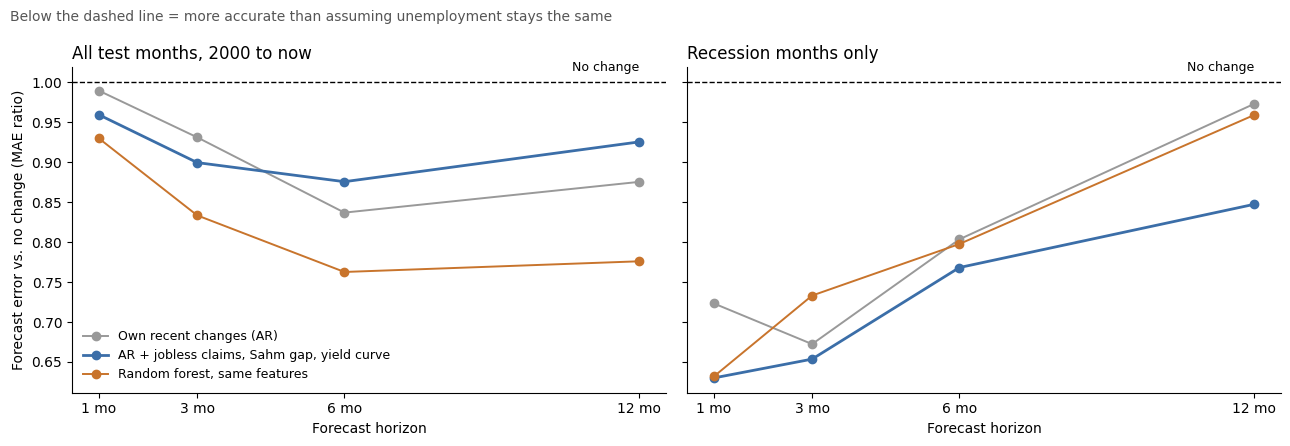

In [21]:
labels = {"no_change": "No change", "ar": "Own recent changes (AR)",
          "ar_claims": "AR + jobless claims, Sahm gap, yield curve", "random_forest": "Random forest, same features"}
colors = {"ar": "#999999", "ar_claims": "#3b6ea8", "random_forest": "#c8742c"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tbl, title in [(axes[0], rel, "All test months, 2000 to now"), (axes[1], rel_rec, "Recession months only")]:
    ax.axhline(1, color="black", lw=1, ls="--")
    ax.text(HORIZONS[-1], 1.01, "No change", ha="right", va="bottom", fontsize=9)
    for k in m_models:
        ax.plot(HORIZONS, tbl[k], marker="o", color=colors[k], lw=2 if k == "ar_claims" else 1.4, label=labels[k])
    ax.set_xticks(HORIZONS, [f"{h} mo" for h in HORIZONS])
    ax.set_xlabel("Forecast horizon")
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Forecast error vs. no change (MAE ratio)")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Below the dashed line = more accurate than assuming unemployment stays the same", x=0.01, ha="left", fontsize=10, color="#555")
fig.tight_layout()
fig.savefig("figures/monthly_horizons.png", dpi=200)
plt.show()

In [22]:
monthly_summary = {
    "months": int(len(m)),
    "sample": f"{m.index.min():%Y-%m} to {m.index.max():%Y-%m}",
    "test_period": f"{mpred.date.min():%Y-%m} to {mpred.date.max():%Y-%m}",
    "covid_excluded": f"{COVID[0]:%Y-%m} to {COVID[1]:%Y-%m}",
    "recession_months_tested_h1": int(mpred[mpred.horizon == 1].recession.sum()),
    "mae_pct_points": {f"{h}m": m_mae.loc[h].round(3).to_dict() for h in HORIZONS},
    "ratio_vs_no_change": {f"{h}m": rel.loc[h].round(3).to_dict() for h in HORIZONS},
    "ratio_vs_no_change_recessions": {f"{h}m": rel_rec.loc[h].round(3).to_dict() for h in HORIZONS},
}
Path("results/monthly_metrics.json").write_text(json.dumps(monthly_summary, indent=2))
mpred.round(3).to_csv("results/monthly_predictions.csv", index=False)
print(json.dumps(monthly_summary, indent=2))

{
  "months": 597,
  "sample": "1977-01 to 2026-10",
  "test_period": "2000-01 to 2026-09",
  "covid_excluded": "2020-03 to 2021-06",
  "recession_months_tested_h1": 26,
  "mae_pct_points": {
    "1m": {
      "no_change": 0.114,
      "ar": 0.113,
      "ar_claims": 0.11,
      "random_forest": 0.106
    },
    "3m": {
      "no_change": 0.216,
      "ar": 0.201,
      "ar_claims": 0.194,
      "random_forest": 0.18
    },
    "6m": {
      "no_change": 0.373,
      "ar": 0.312,
      "ar_claims": 0.326,
      "random_forest": 0.284
    },
    "12m": {
      "no_change": 0.703,
      "ar": 0.615,
      "ar_claims": 0.651,
      "random_forest": 0.546
    }
  },
  "ratio_vs_no_change": {
    "1m": {
      "no_change": 1.0,
      "ar": 0.989,
      "ar_claims": 0.959,
      "random_forest": 0.93
    },
    "3m": {
      "no_change": 1.0,
      "ar": 0.931,
      "ar_claims": 0.899,
      "random_forest": 0.833
    },
    "6m": {
      "no_change": 1.0,
      "ar": 0.837,
      "ar_claim

## Limits

- **Small sample:** about 100 quarters, of which roughly 20 are tested. Treat differences of a few hundredths of a point as noise.
- **The COVID shock:** 2020 is in the training data. The unemployment spike that year is far outside normal variation and can distort what the models learn.
- **Revised data:** FRED serves today's revised figures, not what forecasters saw at the time, so real-time accuracy would be somewhat worse.
- **Importance is not causality:** the feature importance chart shows what the model relies on, not why unemployment moves.